# FIREGUARD ID — 06: Cross-Model Evaluation & Vulnerability Profiling

            - Modules: `src/evaluation/compare_models.py` and `src/vulnerability/assessment.py`.
            - Compares **K-Means (`k=3`)**, **HDBSCAN (`k=8`, 22.39% noise)**, and **DEC (`k=3`)** with explicit noise-scope caveats.
            - Enforces **Cluster ID != Risk Tier**: translates K-Means clusters post-hoc using multi-indicator profiling (`{1: 'Low Observed Activity', 0: 'Moderate / Recurrent', 2: 'High / Chronic-Intense'}`), checks cross-model concordance (**87.34%** with DEC), and evaluates weight sensitivity.


In [1]:
import os
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(REPO_ROOT / ".mplconfig"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import load_yaml, resolve_path

proj_cfg = load_yaml("config/project.yaml", repo_root=REPO_ROOT)
print(f"Project: {proj_cfg['project']['name']} v{proj_cfg['project']['version']} | Pilot: {proj_cfg['project']['pilot_region']}")

from src.evaluation.compare_models import run_phase5_comparison
from src.vulnerability.assessment import profile_clusters, run_phase6_vulnerability_assessment


Project: FIREGUARD-ID v2.0.0 | Pilot: Riau Province, Indonesia


## 1. Cross-Model Comparison Table & Agreement


In [2]:
reports_dir = resolve_path(proj_cfg["paths"]["reports_dir"], repo_root=REPO_ROOT)
processed_dir = resolve_path(proj_cfg["paths"]["processed_dir"], repo_root=REPO_ROOT)

comp_df = pd.read_csv(reports_dir / "clustering" / "model_comparison.csv")
registry = json.loads((reports_dir / "clustering" / "experiment_registry.json").read_text(encoding="utf-8"))
display(comp_df)
print("Cross-model agreement:", json.dumps(registry["cross_model_agreement"], indent=2))
print("Primary Recommendation:", registry["recommendation"]["primary_operational_baseline"])


,model,selected_config,n_clusters,noise_ratio,metric_scope,silhouette_feature,davies_bouldin_feature,calinski_harabasz_feature,multi_seed_mean_ari,spatial_fold_mean_ari,neighbor_concordance,coherence_lift,min_cluster_share,max_cluster_share
0,K-Means (Baseline),"k=3, n_init=30",3,0.000000,All 853 cells (Euclidean feature space),0.544178,0.714354,1261.7150,1.000000,0.972507,0.554477,1.2880,0.091442,0.522860
1,HDBSCAN (Density-Based),"min_cluster_size=15, min_samples=10, method=eom",8,0.223916,Non-noise subset (662/853 cells; 191 noise=-1),0.643293,0.882913,1656.8601,0.971355,0.949771,0.305707,1.4778,0.045317,0.376133
2,DEC (Deep Embedded Clustering),"n_clusters=3, latent_dim=4, gamma_recon=0.1",3,0.000000,All 853 cells (Feature-space eval; Latent Sil=...,0.480230,0.847784,969.6476,0.687657,0.880687,0.514402,1.3212,0.198124,0.520516


Cross-model agreement: {
  "kmeans_vs_dec_ari": 0.770002,
  "kmeans_vs_dec_nmi": 0.71046,
  "kmeans_vs_hdbscan_non_noise_ari": 0.351406,
  "dec_vs_hdbscan_non_noise_ari": 0.351889
}
Primary Recommendation: K-Means (k=3)


## 2. Post-Hoc Cluster Profiles & Vulnerability Assessment


,model,cluster_id,is_noise,n_cells,cell_share_pct,total_hotspots,hotspot_share_pct,zero_detection_cells,mean_hotspot_density_km2,median_hotspot_density_km2,mean_fire_days,median_fire_days,mean_active_years,mean_active_months,mean_frp_total_density_mw_km2,cond_median_frp_p90_mw,cond_mean_dry_season_share,cond_mean_night_share,qa_mean_high_conf_share,dominant_spatial_block
0,K-Means (k=3),1,False,446,52.29,470,3.03,249,0.0127,0.0000,0.79,0.0,0.58,0.67,0.0607,4.35,0.630,0.320,0.0047,SE
1,K-Means (k=3),0,False,329,38.57,5331,34.37,0,0.1497,0.1018,10.63,7.0,3.47,7.11,0.7278,6.99,0.612,0.436,0.0101,NW
2,K-Means (k=3),2,False,78,9.14,9709,62.60,0,1.2520,0.9059,43.92,24.5,4.12,14.27,8.4375,13.83,0.728,0.493,0.0280,NW


K-Means vs DEC Tier Concordance: 87.34 %
Vulnerability Class Distribution: {'Moderate / Recurrent': 329, 'No Detections Observed (QA Caveat)': 249, 'Low / Sporadic Observed': 197, 'High / Chronic-Intense': 78}


,scheme,weights,spearman_rho_vs_equal,top80_jaccard_vs_equal
0,equal_weights_25_25_25_25,"{'hotspot_density_km2': 0.25, 'fire_days': 0.2...",1.000000,1.0000
1,density_heavy_45_20_15_20,"{'hotspot_density_km2': 0.45, 'fire_days': 0.2...",0.997733,0.9277
2,persistence_heavy_15_40_30_15,"{'hotspot_density_km2': 0.15, 'fire_days': 0.4...",0.997117,0.7778
3,intensity_heavy_20_20_15_45,"{'hotspot_density_km2': 0.2, 'fire_days': 0.2,...",0.995799,0.8824


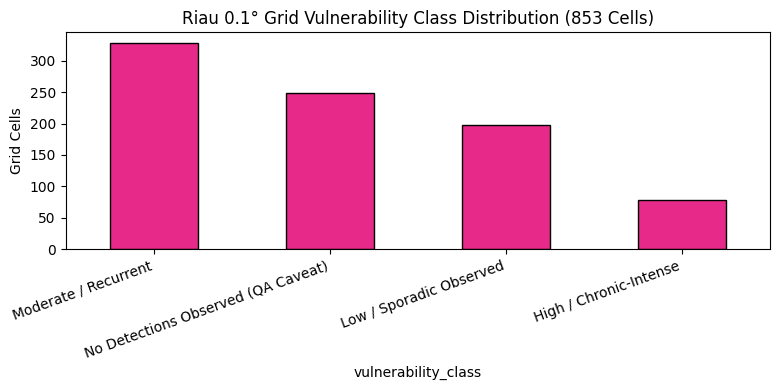

In [3]:
df_vuln = pd.read_parquet(processed_dir / "riau_vulnerability_profile.parquet")
profiles = pd.read_csv(reports_dir / "vulnerability" / "cluster_profiles.csv")
vuln_summary = json.loads((reports_dir / "vulnerability" / "vulnerability_summary.json").read_text(encoding="utf-8"))

display(profiles[profiles["model"] == "K-Means (k=3)"])
print("K-Means vs DEC Tier Concordance:", vuln_summary["kmeans_dec_tier_agreement_pct"], "%")
print("Vulnerability Class Distribution:", vuln_summary["vulnerability_class_counts"])
display(pd.DataFrame(vuln_summary["weight_sensitivity"]))

fig, ax = plt.subplots(figsize=(8, 4))
df_vuln["vulnerability_class"].value_counts().plot(kind="bar", ax=ax, color="#e7298a", edgecolor="black")
ax.set_title("Riau 0.1° Grid Vulnerability Class Distribution (853 Cells)")
ax.set_ylabel("Grid Cells")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()
